# Potassium-enriched salt in a vivarium simulation: a tour on made-up data

This notebook walks through the model in this directory from inputs to answer, for one country. The country is "Testland", which does not exist. The real inputs are GBD estimates that are not kept in the repository, so I use synthetic numbers in the same layout, which is enough to show how the pieces fit together and not enough to learn anything about salt.

The steps are the ones a vivarium model usually takes: ask for inputs by `gbd_mapping` entity through a `vivarium_inputs`-shaped interface, build an artifact, run a simulation (here interactively), and turn what the observers recorded into the quantity of interest. At the end I check the simulation against a closed-form version of the same model, which is a luxury most simulations do not have.

In [1]:
import os, tempfile

root = tempfile.mkdtemp(prefix="potassium_salt_tutorial_")
os.environ["POTASSIUM_SALT_ROOT"] = root     # must be set before the package is imported

from vivarium_potassium_salt.data import synthetic
synthetic.write_inputs(root)
sorted(p.name for p in (synthetic.Path(root) / "data" / "gbd_2023").iterdir())

['burden_25_plus.csv',
 'burden_by_age.csv',
 'burden_region_by_age.csv',
 'ckd_stage_global_by_age.csv',
 'exposure.csv',
 'population.csv']

## 1. Inputs, asked for the way vivarium asks

On the IHME cluster a model gets its data by handing a `gbd_mapping` entity to `vivarium_inputs.get_measure`. That package cannot be installed off the cluster, so `vivarium_inputs_stub` offers the same call and answers it from the CSV files written above (or, for the real analysis, from a cached GBD 2023 extract). The return value has the usual shape: a row per sex and age band, and a column per draw.

In [2]:
from vivarium.gbd_mapping import causes, risk_factors
from vivarium_potassium_salt.data import vivarium_inputs_stub as interface

sbp = interface.get_measure(risk_factors.high_systolic_blood_pressure, "exposure", "Testland")
sbp.iloc[:3, :2].round(1)

draw_0  \
location sex    age_start age_end year_start year_end parameter            
Testland Female 25.0      30.0    2021       2022     continuous   115.2   
                30.0      35.0    2021       2022     continuous   118.4   
                35.0      40.0    2021       2022     continuous   120.2   

                                                                  draw_1  
location sex    age_start age_end year_start year_end parameter           
Testland Female 25.0      30.0    2021       2022     continuous   115.8  
                30.0      35.0    2021       2022     continuous   117.6  
                35.0      40.0    2021       2022     continuous   119.1

In [3]:
interface.get_measure(
    causes.ischemic_heart_disease, "cause_specific_mortality_rate", "Testland", data_type="means"
).tail(3)

value
location sex  age_start age_end year_start year_end          
Testland Male 85.0      90.0    2021       2022      0.016986
              90.0      95.0    2021       2022      0.025851
              95.0      125.0   2021       2022      0.039345

## 2. The artifact

The artifact is one HDF file with everything the simulation of a location needs. I follow one convention that is not standard: **draw 0 holds the mean of every input**, so that `input_draw_number: 0` runs the model at central values, and draws 1 and up are samples.

In [4]:
from vivarium.artifact import Artifact
from vivarium_potassium_salt.data import builder

artifact = Artifact(builder.build_artifact("Testland"))
[key for key in artifact.keys if not key.startswith("cause.")]

['metadata.keyspace',
 'population.location',
 'population.structure',
 'population.age_bins',
 'population.demographic_dimensions',
 'risk_factor.high_systolic_blood_pressure.exposure',
 'risk_factor.high_systolic_blood_pressure.exposure_standard_deviation',
 'risk_factor.high_systolic_blood_pressure.exposure_distribution_weights',
 'risk_factor.high_systolic_blood_pressure.distribution',
 'risk_factor.high_systolic_blood_pressure.tmred',
 'risk_factor.high_systolic_blood_pressure.relative_risk_scalar',
 'risk_factor.high_systolic_blood_pressure.relative_risk',
 'risk_factor.high_systolic_blood_pressure.population_attributable_fraction',
 'risk_factor.diet_high_in_sodium.exposure',
 'risk_factor.diet_high_in_sodium.discretionary_share',
 'risk_factor.diet_high_in_sodium.reported_discretionary_share',
 'ncd_risc.hypertension.prevalence',
 'ncd_risc.hypertension.proportion_diagnosed',
 'ncd_risc.hypertension.proportion_treated',
 'risk_factor.kidney_dysfunction.exposure',
 'risk_factor.

## 3. Two simulations that share their simulants

A simulation is the model specification plus a scenario. `build_simulation` returns a `vivarium.interactive` simulation with its 15,000 simulants created and no time step taken, so everything about them can be inspected. Here are the baseline and the scenario that replaces all salt, with the same random seed.

In [5]:
from vivarium_potassium_salt.tools import run_simulation

baseline = run_simulation.build_simulation("Testland", "baseline")
all_salt = run_simulation.build_simulation("Testland", "all_salt")

columns = ["age", "sex", "hypertension_status", "diet_high_in_sodium.exposure",
           "salt_substitute.sodium_reduction", "salt_substitute.sbp_reduction",
           "high_systolic_blood_pressure.exposure"]
all_salt.get_population(columns).head().round(2)

,age,sex,hypertension_status,diet_high_in_sodium.exposure,salt_substitute.sodium_reduction,salt_substitute.sbp_reduction,high_systolic_blood_pressure.exposure
0,25.50,Female,undiagnosed_hypertension,3.68,0.92,5.12,109.77
1,31.07,Female,normotensive,3.55,0.89,4.34,118.07
2,39.44,Female,normotensive,3.42,0.86,4.21,129.59
3,40.94,Female,normotensive,3.30,0.82,4.09,134.37
4,47.00,Female,normotensive,3.17,0.79,4.15,101.41


Because the seed is shared, simulant 0 is the same person in both simulations, with the same age, hypertension status, and place in the blood pressure distribution. The only difference between the two is the intervention, which is what makes the comparison below a comparison of like with like (the simulation literature calls this common random numbers).

In [6]:
before, after = baseline.get_population(columns), all_salt.get_population(columns)
pressure = "high_systolic_blood_pressure.exposure"
fall = before[pressure] - after[pressure]
assert (before["age"] == after["age"]).all()
assert abs(fall - after["salt_substitute.sbp_reduction"]).max() < 1e-9
fall.describe().round(2)

count    15000.00
mean         3.90
std          1.62
min          0.00
25%          3.12
50%          4.23
75%          5.12
max          6.59
Name: high_systolic_blood_pressure.exposure, dtype: float64

The fall in systolic blood pressure is larger with hypertension, which is the gap between the two lines below and comes from the sodium dose-response the paper takes from Mozaffarian et al. (2014). Per gram of sodium removed the effect also grows with age, but in Testland the fall shrinks with age, because its made-up sodium intake does. At the oldest ages the women are already below 2 g/day of sodium, where the paper assumes no further benefit, and only the men pull the average above zero.

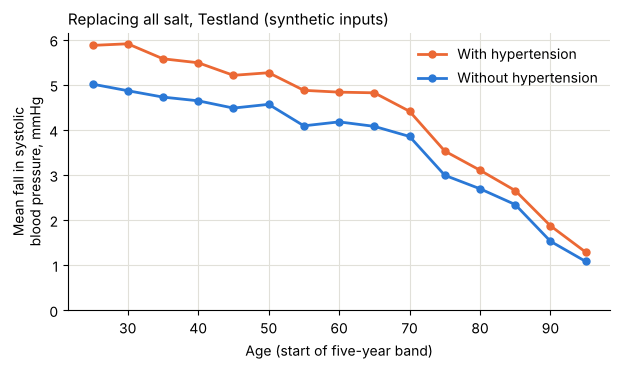

In [7]:
import matplotlib.pyplot as plt

after["Age band"] = (after["age"] // 5 * 5).astype(int)
after["Hypertension"] = after["hypertension_status"].ne("normotensive").map(
    {True: "With hypertension", False: "Without hypertension"})
mean_fall = after.groupby(["Age band", "Hypertension"])["salt_substitute.sbp_reduction"].mean().unstack()

fig, ax = plt.subplots(figsize=(7, 3.6))
for name, colour in (("With hypertension", "#eb6834"), ("Without hypertension", "#2a78d6")):
    ax.plot(mean_fall.index, mean_fall[name], color=colour, linewidth=2, marker="o", markersize=5, label=name)
ax.set_xlabel("Age (start of five-year band)")
ax.set_ylabel("Mean fall in systolic\nblood pressure, mmHg")
ax.set_ylim(0)
ax.grid(color="#e1e0d9", linewidth=0.8)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
ax.set_title("Replacing all salt, Testland (synthetic inputs)", loc="left", fontsize=11);

## 4. One step, and the observers

The paper's model is a static comparative risk assessment for one year, so the simulation takes a single one-year step and nobody dies in it. Each simulant instead carries an annual death rate for each cause, which is the GBD rate for their age and sex times their relative risk (from the `RiskEffect` on blood pressure), and an observer adds those rates up by stratum. The sum of rates is the expected number of deaths among the simulants, without the noise of drawing them.

In [8]:
baseline.step()
all_salt.step()
burden = {"baseline": baseline.get_results()["burden"], "all_salt": all_salt.get_results()["burden"]}
rate = "ischemic_heart_disease.cause_specific_mortality_rate"
burden["baseline"][["age_group", "sex", "ckd_stage", rate, "person_count"]].head(4)

,age_group,sex,ckd_stage,ischemic_heart_disease.cause_specific_mortality_rate,person_count
0,25_to_29,Female,none,0.043055,492.0
1,25_to_29,Male,none,0.055581,495.0
2,25_to_29,Female,G3a,0.000444,6.0
3,25_to_29,Male,G3a,0.000668,4.0


The share of deaths averted in a stratum (the potential impact fraction) is one minus the ratio of the two sums.

In [9]:
sums = {name: table.groupby(["age_group", "sex"], observed=True)[rate].sum()
        for name, table in burden.items()}
simulated = (1 - sums["all_salt"] / sums["baseline"]).unstack("sex")
simulated.iloc[[0, 5, 10, 14]].round(3)

sex,Female,Male
age_group,,
25_to_29,0.192,0.268
50_to_54,0.143,0.176
75_to_79,0.055,0.103
95_plus,0.000,0.055


## 5. The same answer in closed form

With blood pressure gamma distributed and a log-linear relative risk above the TMREL, the average that the simulation estimates has an exact expression in incomplete gamma functions (`analytic.py`). The simulation and the closed form share the dose-response arithmetic and nothing else, so their agreement says the components, the risk effects, and the observers are wired as intended.

In [10]:
import pandas as pd
from vivarium_potassium_salt import analytic
from vivarium_potassium_salt.constants import metadata

inputs = analytic.load_inputs("Testland")
exact = analytic.evaluate(inputs)["all_salt"]["pif"][metadata.CAUSES.index("ischemic_heart_disease"), :, 0]
exact = pd.Series(exact, index=pd.MultiIndex.from_frame(inputs.strata[["age_group", "sex"]])).unstack("sex")
exact.index = exact.index.str.replace(" ", "_")
(simulated - exact.reindex(simulated.index)).abs().max().round(4)

sex
Female    0.0047
Male      0.0034
dtype: float64

The largest difference in any stratum is under half a percentage point. Summed over causes and strata, deaths averted agree to about one part in a thousand. The kidney-disease quantities rest on the few hundred simulants with advanced kidney disease, and agree to a few percent:

In [11]:
from vivarium_potassium_salt.tools import analysis

results = {name: pd.concat([sim.get_results()[name].assign(location="Testland", scenario=scenario, draw=0)
                            for scenario, sim in (("baseline", baseline), ("all_salt", all_salt))])
           for name in ("burden", "salt_policy")}
_, totals = analysis.summarise_simulation(results["burden"], results["salt_policy"])
closed = analytic.run_location("Testland")["draw_0"].groupby(["scenario", "quantity"]).sum()
table = pd.DataFrame({"simulation": totals.groupby(["scenario", "quantity"])["value"].sum(),
                      "closed form": closed}).loc["all_salt"]
table.assign(ratio=table["simulation"] / table["closed form"]).round(3)

,simulation,closed form,ratio
quantity,,,
deaths_averted__ckd,2.624090e+02,2.625870e+02,0.999
deaths_averted__cvd,4.755545e+03,4.755398e+03,1.000
hyperkalaemia_deaths,1.029540e+02,1.021420e+02,1.008
prevented_cvd_deaths_in_ckd,1.105279e+03,1.081836e+03,1.022
users,1.765797e+07,1.765797e+07,1.000


## What changes with real data

Nothing in the steps above. The real analysis points the same code at a cached extract of GBD 2023 for 193 countries (`gbd_pull/`), and on the IHME cluster the one import in `data/loader.py` can be switched from the stub to `vivarium_inputs`. The README has the results, and says where they do and do not match the paper.